<a href="https://colab.research.google.com/github/ShouryaBatra/fbla-data-analysis/blob/main/charts1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Path to uploaded font (adjust if needed)
font_path = "/content/Raleway-Regular.ttf"

# Register font
fm.fontManager.addfont(font_path)

# Set as default
plt.rcParams["font.family"] = "Raleway"

In [ ]:
# Slide-matching colors (approx)
NAVY = "#22364D"      # header/navy
BLUE = "#2F80ED"      # bright blue
MIDBLUE = "#2B6CB0"   # slightly darker blue
TEXT = "#1B1B1B"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#D0D0D0",
    "axes.labelcolor": TEXT,
    "xtick.color": TEXT,
    "ytick.color": TEXT,
    "text.color": TEXT,
    "font.size": 13,
    "axes.titleweight": "bold",
    "axes.titlesize": 18,
    "axes.labelsize": 14,
})


In [ ]:
athletes = pd.read_csv("athlete_events.csv")
nocs = pd.read_csv("noc_regions.csv")

df = athletes.merge(nocs, on="NOC", how="left")
df = df[df["Season"] == "Summer"].copy()
df = df.rename(columns={"region": "Country"})


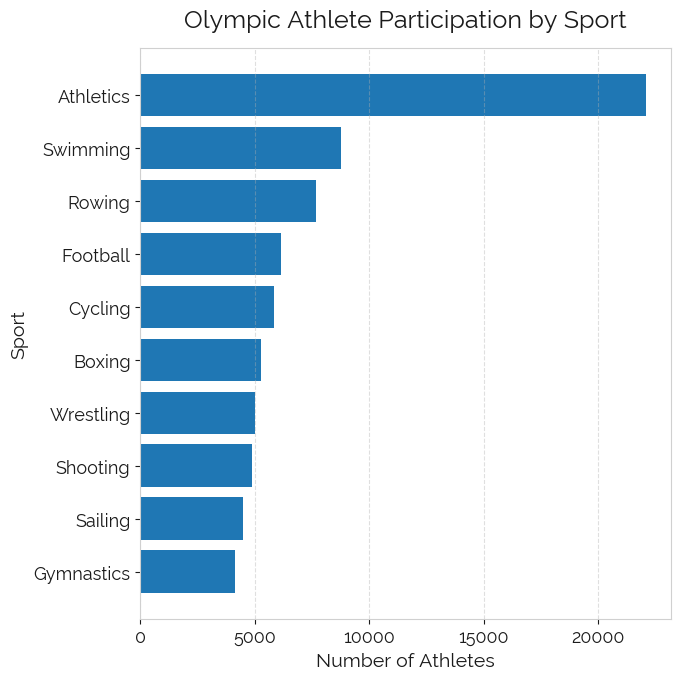

In [ ]:
sport_participation = (
    df.groupby("Sport")["ID"]
    .nunique()
    .sort_values(ascending=True)
    .tail(10)
)

plt.figure(figsize=(7, 7))
plt.barh(sport_participation.index, sport_participation.values)

plt.title("Olympic Athlete Participation by Sport", fontsize=18, pad=15)
plt.xlabel("Number of Athletes", fontsize=14)
plt.ylabel("Sport", fontsize=14)

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

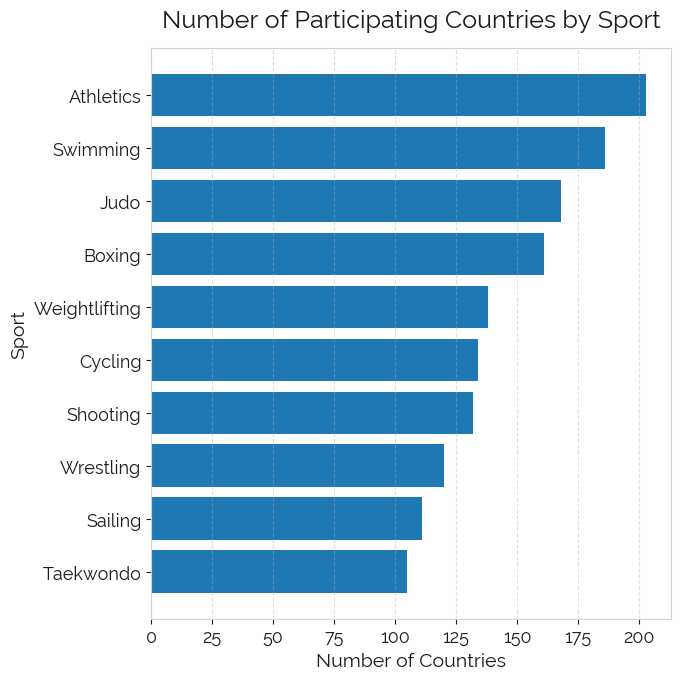

In [ ]:
countries_per_sport = (
    df.groupby("Sport")["Country"]
    .nunique()
    .sort_values(ascending=True)
    .tail(10)
)

plt.figure(figsize=(7, 7))
plt.barh(countries_per_sport.index, countries_per_sport.values)

plt.title("Number of Participating Countries by Sport", fontsize=18, pad=15)
plt.xlabel("Number of Countries", fontsize=14)
plt.ylabel("Sport", fontsize=14)

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()